In [38]:
import tensorflow as tf
import numpy as np  
import pandas as pd  
import matplotlib.pyplot as plt  
import seaborn as sns  

from sklearn.model_selection import train_test_split 
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay, f1_score 
import torch
import torch.nn as nn
from torchsummary import summary
from torch.utils.data import DataLoader,Dataset
from sklearn.preprocessing import StandardScaler, LabelEncoder 

from helper import fn_plot_tf_hist

In [33]:
RANDOM_STATE = 24 
np.random.seed(RANDOM_STATE)
rng = np.random.default_rng(seed = RANDOM_STATE) # Set Random Seed for reproducible  results
tf.random.set_seed(RANDOM_STATE)

EPOCHS = 25 # number of epochs
BATCH_SIZE = 32
WEIGHT_DECAY=1e-4
ALPHA = 0.001 # learning rate
TEST_SIZE = int(BATCH_SIZE*18)
PATIENCE=20
LR_PATIENCE=5
LR_FACTOR=0.1


params = {'legend.fontsize': 'x-large',
          'figure.figsize': (15, 6),
          'axes.labelsize': 'x-large',
          'axes.titlesize':'x-large',
          'xtick.labelsize':'x-large',
          'ytick.labelsize':'x-large'
         }

plt.rcParams.update(params)

CMAP = plt.cm.coolwarm
plt.style.use('seaborn-v0_8-darkgrid')

In [ ]:
df=pd.read_csv(r"C:\Users\PGCP-AI\Downloads\fashion-mnist_train.csv")
df.head()


,label,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,pixel9,...,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783,pixel784
0,2,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,9,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,6,0,0,0,0,0,0,0,5,0,...,0,0,0,30,43,0,0,0,0,0
3,0,0,0,0,1,2,0,0,0,0,...,3,0,0,0,0,1,0,0,0,0
4,3,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [15]:
X_train=df.drop('label',axis=1)
X_train=X_train/255
y_train= df['label']

In [21]:
test_df=pd.read_csv(r"C:\Users\PGCP-AI\Downloads\fashion-mnist_test.csv")


In [22]:
X_test=df.drop('label',axis=1)
X_test=X_test/255
y_test= df['label']

In [ ]:
train_ds=tf.data.Dataset.from_tensor_slices((X_train,y_train))
train_ds=train_ds.cache(22)

train_ds = train_ds.shuffle(buffer_size=X_train.shape[0]).batch(BATCH_SIZE)
train_ds = train_ds.prefetch(buffer_size=tf.data.AUTOTUNE)

In [25]:
test_ds=tf.data.Dataset.from_tensor_slices((X_test,y_test))
test_ds=test_ds.cache()

test_ds = test_ds.shuffle(buffer_size=X_test.shape[0]).batch(BATCH_SIZE)
test_ds = test_ds.prefetch(buffer_size=tf.data.AUTOTUNE)

In [18]:
for features, label in train_ds.take(1):
    print(features.shape,label.shape)

(32, 784) (32,)


In [28]:
initializer= tf.keras.initializers.GlorotUniform(seed=RANDOM_STATE)
optimizer=tf.keras.optimizers.Adam(learning_rate=ALPHA)

loss_fn=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True)

model=tf.keras.models.Sequential([
        tf.keras.Input(shape=(X_train.shape[1],)),

        tf.keras.layers.Dense(392,activation=tf.nn.relu,kernel_initializer=initializer),

        tf.keras.layers.Dense(196,activation=tf.nn.relu,kernel_initializer=initializer),

        tf.keras.layers.Dense(98,activation=tf.nn.relu,kernel_initializer=initializer),

        tf.keras.layers.Dense(49,activation=tf.nn.relu,kernel_initializer=initializer),

        tf.keras.layers.Dense(10)
    ]
)

In [29]:
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_5 (Dense)                 │ (None, 392)            │       307,720 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 196)            │        77,028 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 98)             │        19,306 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 49)             │         4,851 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 10)             │           500 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 409,405 (1.56 MB)

 Trainable params: 409,405 (1.56 MB)

 Non-trainable params: 0 (0.00 B)

In [32]:
model.compile(
    optimizer=optimizer,
    loss=loss_fn,
    metrics=['accuracy']
)

In [34]:
history=model.fit(train_ds,validation_data=test_ds,epochs=EPOCHS)

Epoch 1/25


C:\Users\PGCP-AI\AppData\Roaming\Python\Python314\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


1875/1875 ━━━━━━━━━━━━━━━━━━━━ 17s 8ms/step - accuracy: 0.8185 - loss: 0.5013 - val_accuracy: 0.8638 - val_loss: 0.3692
Epoch 2/25
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 15s 8ms/step - accuracy: 0.8630 - loss: 0.3755 - val_accuracy: 0.8688 - val_loss: 0.3591
Epoch 3/25
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 15s 8ms/step - accuracy: 0.8759 - loss: 0.3389 - val_accuracy: 0.8916 - val_loss: 0.2988
Epoch 4/25
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 15s 8ms/step - accuracy: 0.8828 - loss: 0.3165 - val_accuracy: 0.8949 - val_loss: 0.2805
Epoch 5/25
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 15s 8ms/step - accuracy: 0.8912 - loss: 0.2941 - val_accuracy: 0.9018 - val_loss: 0.2646
Epoch 6/25
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 15s 8ms/step - accuracy: 0.8946 - loss: 0.2807 - val_accuracy: 0.8942 - val_loss: 0.2909
Epoch 7/25
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 15s 8ms/step - accuracy: 0.8987 - loss: 0.2687 - val_accuracy: 0.9116 - val_loss: 0.2368
Epoch 8/25
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 15s 8ms/step - accuracy: 0.9025 - loss: 0.2593 - val

In [35]:
loss_df=pd.DataFrame(history.history)
loss_df.head()

,accuracy,loss,val_accuracy,val_loss
0,0.818517,0.501291,0.863850,0.369152
1,0.863000,0.375470,0.868767,0.359140
2,0.875867,0.338895,0.891600,0.298815
3,0.882850,0.316467,0.894917,0.280495
4,0.891233,0.294064,0.901783,0.264554


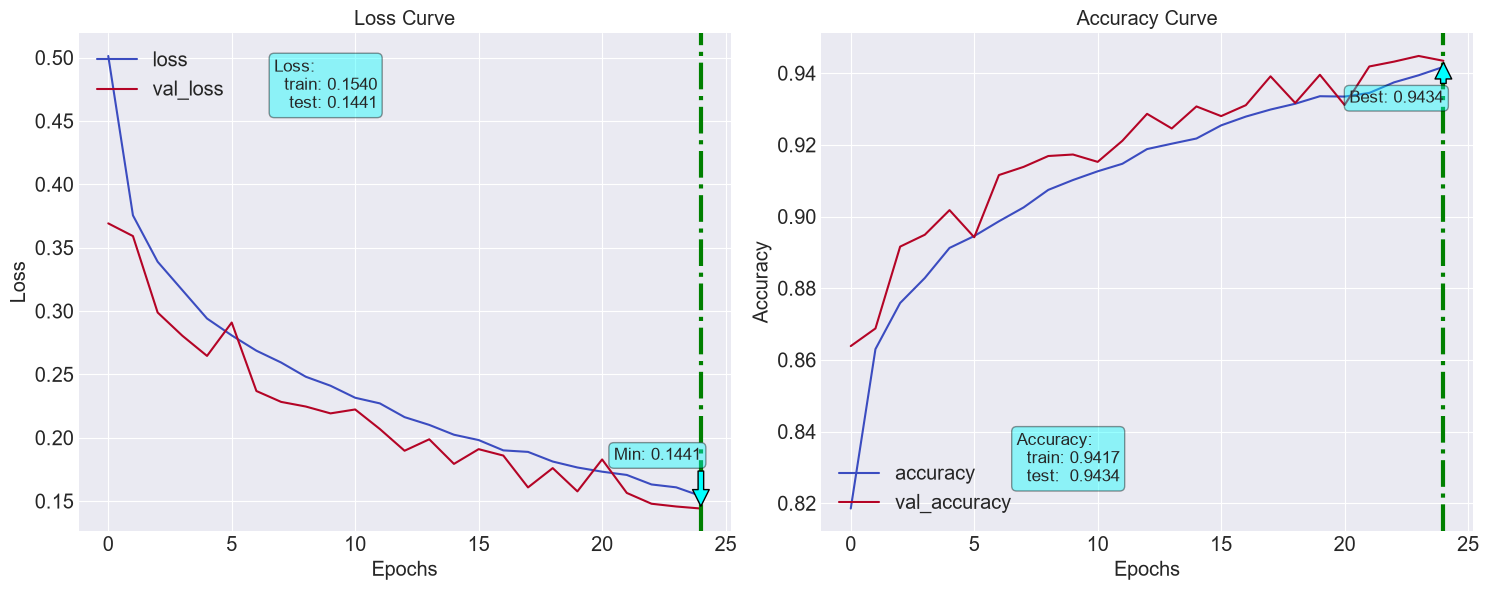

In [39]:
fn_plot_tf_hist(loss_df)

## After Regularization

In [40]:
initializer= tf.keras.initializers.GlorotUniform(seed=RANDOM_STATE)
optimizer=tf.keras.optimizers.Adam(learning_rate=ALPHA)

loss_fn=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True)

regularizer=tf.keras.regularizers.l2(l2=0.02)
model_reg=tf.keras.models.Sequential([
        tf.keras.Input(shape=(X_train.shape[1],)),

        tf.keras.layers.Dense(392,activation=tf.nn.relu,kernel_initializer=initializer,
        kernel_regularizer=regularizer),

        tf.keras.layers.Dense(196,activation=tf.nn.relu,kernel_initializer=initializer,
        kernel_regularizer=regularizer),

        tf.keras.layers.Dense(98,activation=tf.nn.relu,kernel_initializer=initializer,
        kernel_regularizer=regularizer),

        tf.keras.layers.Dense(49,activation=tf.nn.relu,kernel_initializer=initializer,
        kernel_regularizer=regularizer),

        tf.keras.layers.Dense(10)
    ]
)

In [41]:
model_reg.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_10 (Dense)                │ (None, 392)            │       307,720 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 196)            │        77,028 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_12 (Dense)                │ (None, 98)             │        19,306 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ (None, 49)             │         4,851 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_14 (Dense)                │ (None, 10)             │           500 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 409,405 (1.56 MB)

 Trainable params: 409,405 (1.56 MB)

 Non-trainable params: 0 (0.00 B)

In [42]:
model_reg.compile(
    optimizer=optimizer,
    loss=loss_fn,
    metrics=['accuracy']
)

In [43]:
history=model_reg.fit(train_ds,validation_data=test_ds,epochs=EPOCHS)


Epoch 1/25


C:\Users\PGCP-AI\AppData\Roaming\Python\Python314\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


1875/1875 ━━━━━━━━━━━━━━━━━━━━ 16s 8ms/step - accuracy: 0.7213 - loss: 1.6785 - val_accuracy: 0.7470 - val_loss: 1.0501
Epoch 2/25
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 15s 8ms/step - accuracy: 0.7654 - loss: 0.9767 - val_accuracy: 0.7701 - val_loss: 0.9081
Epoch 3/25
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 15s 8ms/step - accuracy: 0.7763 - loss: 0.9173 - val_accuracy: 0.7961 - val_loss: 0.8680
Epoch 4/25
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 15s 8ms/step - accuracy: 0.7821 - loss: 0.8806 - val_accuracy: 0.7988 - val_loss: 0.8553
Epoch 5/25
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 15s 8ms/step - accuracy: 0.7896 - loss: 0.8508 - val_accuracy: 0.8064 - val_loss: 0.8096
Epoch 6/25
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 15s 8ms/step - accuracy: 0.7932 - loss: 0.8297 - val_accuracy: 0.8038 - val_loss: 0.8123
Epoch 7/25
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 20s 10ms/step - accuracy: 0.7943 - loss: 0.8177 - val_accuracy: 0.7664 - val_loss: 0.8523
Epoch 8/25
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 15s 8ms/step - accuracy: 0.7987 - loss: 0.7993 - va

In [44]:
loss_df=pd.DataFrame(history.history)
loss_df.head()

,accuracy,loss,val_accuracy,val_loss
0,0.721267,1.678457,0.747017,1.050092
1,0.765433,0.976675,0.770083,0.908059
2,0.776317,0.917317,0.796133,0.867993
3,0.782100,0.880622,0.798850,0.855305
4,0.789583,0.850766,0.806417,0.809642


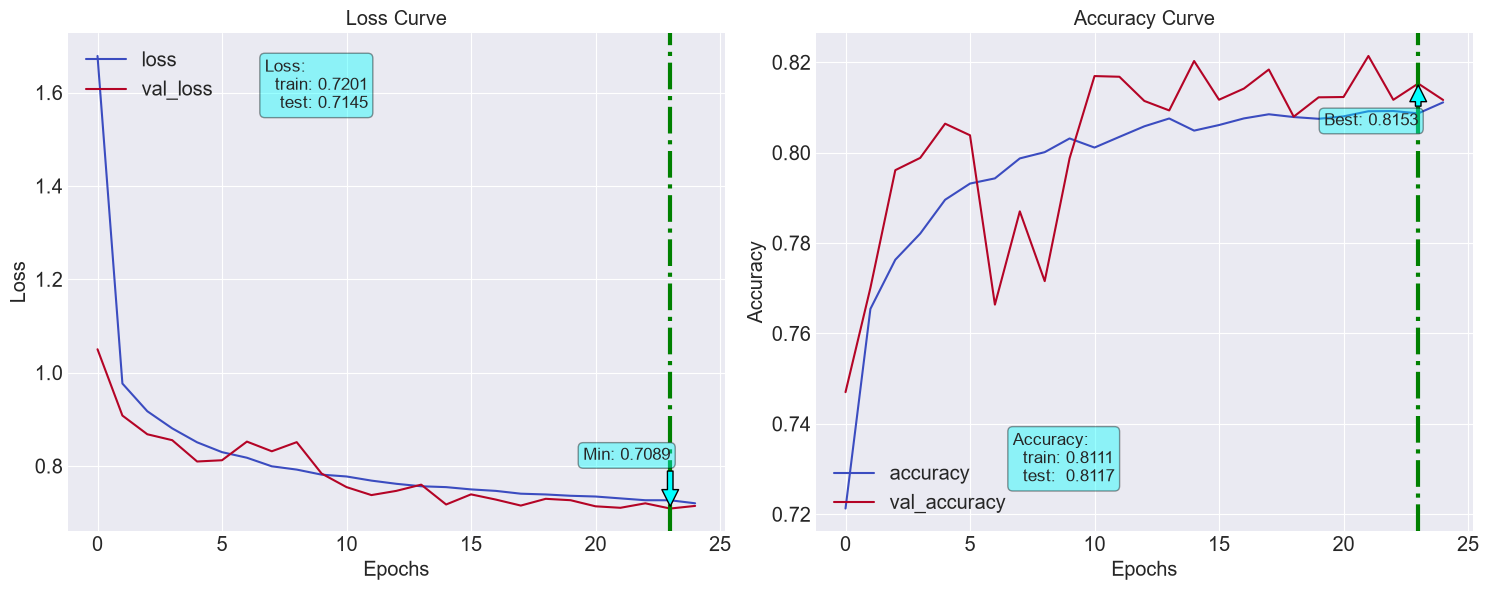

In [45]:
fn_plot_tf_hist(loss_df)
